# Battery State-of-Health & Degradation Models (NASA PCoE data)

**Author:** Dhanush Vel Nithi M  ·  **Status:** research notebook, open and reproducible

**Question 1 (SoH estimation):** can a model estimate a cell's state of health (SoH) from the shape of a single discharge curve, on a cell it has never seen?
**Question 2 (degradation forecasting):** can a model forecast SoH 10 cycles ahead better than a naive baseline?

**Data:** NASA Prognostics Center of Excellence Li-ion battery data set (B. Saha and K. Goebel, 2007), cells B0005, B0006, B0007 and B0018 (2 Ah 18650 cells, room temperature, constant-current discharge).
**SoH definition:** SoH = discharge capacity / 2.0 Ah (rated capacity).
**Evaluation rule:** *leave-one-battery-out* — train on three cells, test on the fourth. No cycle from the test cell is ever used for training, so there is no leakage between cells.
Models: Decision Tree, KNN, XGBoost, plus simple baselines. Nothing here is tuned on the test cell.

In [1]:
import os, urllib.request, warnings
import numpy as np, pandas as pd, scipy.io as sio
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
SEED=0; np.random.seed(SEED)
CELLS=["B0005","B0006","B0007","B0018"]
RATED_AH=2.0
os.makedirs("data",exist_ok=True)

## 1. Load the data
The `.mat` files are public NASA data. This notebook downloads them from a public GitHub mirror (original source: NASA Prognostics Data Repository). Nothing is redistributed in this repo.

In [2]:
MIRROR="https://raw.githubusercontent.com/psanabriaUC/BatteryDatasetImplementation/master/battery_data/{}.mat"
for c in CELLS:
    p=f"data/{c}.mat"
    if not os.path.exists(p):
        urllib.request.urlretrieve(MIRROR.format(c),p)
print({c:os.path.getsize(f"data/{c}.mat")//1024 for c in CELLS},"KB")

{'B0005': 15582, 'B0006': 15652, 'B0007': 15673, 'B0018': 8302} KB


## 2. Per-cycle features
For each *discharge* cycle: capacity (the label), and features computed from the voltage/temperature curve.
`duration_s` is **deliberately excluded**: under a constant-current discharge it is almost proportional to capacity, so it would leak the label.

In [3]:
def cycle_features(d):
    v=np.asarray(d["Voltage_measured"],float); t=np.asarray(d["Temperature_measured"],float); tm=np.asarray(d["Time"],float)
    n=max(len(v)//3,3)
    slope=np.polyfit(tm[:n],v[:n],1)[0]
    return dict(v_mean=v.mean(), v_std=v.std(), v_min=v.min(), frac_below_3p5=(v<3.5).mean(),
                v_slope_first_third=slope, t_mean=t.mean(), t_max=t.max(), t_rise=t.max()-t[0])

rows=[]
for c in CELLS:
    m=sio.loadmat(f"data/{c}.mat",simplify_cells=True)[c]["cycle"]
    k=0
    for x in m:
        if x["type"]!="discharge": continue
        d=x["data"]; cap=float(np.atleast_1d(d["Capacity"])[0])
        f=cycle_features(d); k+=1
        rows.append(dict(cell=c,cycle=k,capacity=cap,soh=cap/RATED_AH,**f))
df=pd.DataFrame(rows)
FEATS=["cycle","v_mean","v_std","v_min","frac_below_3p5","v_slope_first_third","t_mean","t_max","t_rise"]
summary=df.groupby("cell").agg(discharge_cycles=("cycle","max"),first_soh=("soh","first"),last_soh=("soh","last"),min_soh=("soh","min")).round(3)
summary

,discharge_cycles,first_soh,last_soh,min_soh
cell,,,,
B0005,168,0.928,0.663,0.644
B0006,168,1.018,0.593,0.577
B0007,168,0.946,0.716,0.700
B0018,132,0.928,0.671,0.671


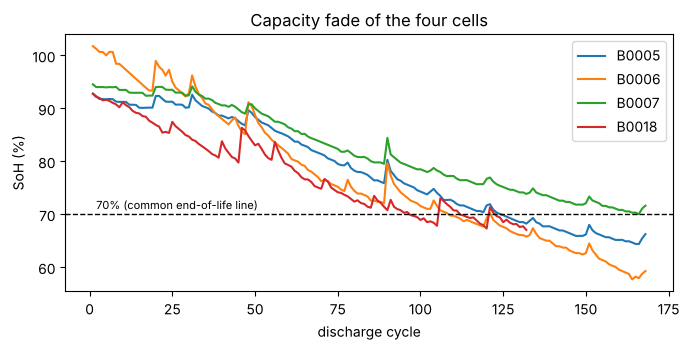

In [4]:
fig,ax=plt.subplots(figsize=(7,3.6))
for c in CELLS: s=df[df.cell==c]; ax.plot(s.cycle,s.soh*100,label=c)
ax.axhline(70,color="k",ls="--",lw=1); ax.text(2,71,"70% (common end-of-life line)",fontsize=8)
ax.set_xlabel("discharge cycle"); ax.set_ylabel("SoH (%)"); ax.legend(); ax.set_title("Capacity fade of the four cells"); plt.tight_layout(); plt.show()

## 3. Task 1 — SoH estimation from one discharge curve (leave-one-battery-out)
Metrics are in **SoH percentage points** (1.0 = one point of SoH). Baselines: predicting the training mean, and a straight line on `cycle` only.

In [5]:
def models():
    return {
     "Mean baseline":DummyRegressor(),
     "Linear (cycle only)":None,
     "Decision Tree":DecisionTreeRegressor(max_depth=5,random_state=SEED),
     "KNN (k=5)":make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=5)),
     "XGBoost":XGBRegressor(n_estimators=300,max_depth=3,learning_rate=0.05,subsample=0.8,random_state=SEED,n_jobs=2),
    }
def metrics(y,p): return mean_absolute_error(y,p)*100, np.sqrt(mean_squared_error(y,p))*100

res=[]; preds={}
for held in CELLS:
    tr=df[df.cell!=held]; te=df[df.cell==held]
    for name,mdl in models().items():
        if name=="Linear (cycle only)":
            mdl=LinearRegression(); X1,X2=tr[["cycle"]],te[["cycle"]]
        else: X1,X2=tr[FEATS],te[FEATS]
        mdl.fit(X1,tr.soh); p=mdl.predict(X2); mae,rmse=metrics(te.soh,p)
        res.append(dict(held_out=held,model=name,MAE=mae,RMSE=rmse)); preds[(held,name)]=p
r1=pd.DataFrame(res)
tab1=r1.pivot(index="model",columns="held_out",values="MAE"); tab1["mean MAE"]=tab1.mean(axis=1)
tab1.round(2).sort_values("mean MAE")

held_out,B0005,B0006,B0007,B0018,mean MAE
model,,,,,
XGBoost,1.49,2.75,1.66,2.13,2.01
Decision Tree,2.32,2.76,2.41,2.35,2.46
Linear (cycle only),1.25,4.52,5.34,5.18,4.07
KNN (k=5),3.94,4.52,4.01,7.59,5.01
Mean baseline,8.56,11.35,7.43,7.03,8.59


In [6]:
tab1r=r1.pivot(index="model",columns="held_out",values="RMSE"); tab1r["mean RMSE"]=tab1r.mean(axis=1)
tab1r.round(2).sort_values("mean RMSE")

held_out,B0005,B0006,B0007,B0018,mean RMSE
model,,,,,
XGBoost,1.74,3.66,2.05,2.88,2.58
Decision Tree,2.52,3.74,2.94,3.54,3.18
Linear (cycle only),1.54,4.88,5.96,5.52,4.48
KNN (k=5),4.88,5.11,4.72,8.18,5.72
Mean baseline,9.51,12.78,9.09,7.86,9.81


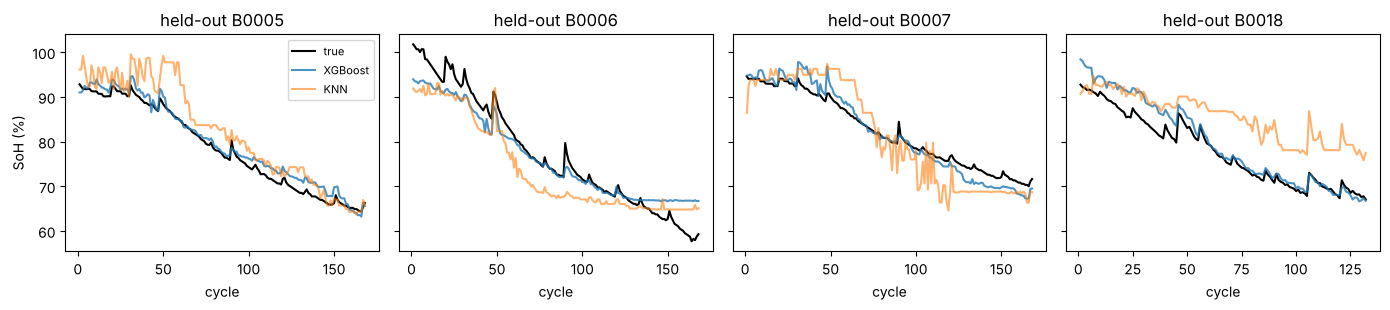

In [7]:
fig,axs=plt.subplots(1,4,figsize=(14,3.2),sharey=True)
for ax,held in zip(axs,CELLS):
    te=df[df.cell==held]; ax.plot(te.cycle,te.soh*100,"k",label="true")
    ax.plot(te.cycle,preds[(held,"XGBoost")]*100,label="XGBoost",alpha=.8); ax.plot(te.cycle,preds[(held,"KNN (k=5)")]*100,label="KNN",alpha=.6)
    ax.set_title(f"held-out {held}"); ax.set_xlabel("cycle")
axs[0].set_ylabel("SoH (%)"); axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. Task 2 — degradation forecasting: SoH 10 cycles ahead
Input: the last 5 SoH values (a BMS would have these from earlier capacity checks). Target: SoH 10 cycles later, modelled as the *change* from the current SoH.
Baselines: **persistence** (no change) and **linear extrapolation** of the last 5 points. A forecasting model is only useful if it beats these.

In [8]:
H=10; W=5
def make_xy(s):
    soh=s.soh.values; X=[];y=[];base=[]
    for t in range(W-1,len(soh)-H):
        w=soh[t-W+1:t+1]; X.append(np.r_[w,w[-1]-w[0],t]); y.append(soh[t+H]); base.append(w[-1])
    return np.array(X),np.array(y),np.array(base)
data={c:make_xy(df[df.cell==c]) for c in CELLS}
res=[]
for held in CELLS:
    Xtr=np.vstack([data[c][0] for c in CELLS if c!=held]); ytr=np.concatenate([data[c][1] for c in CELLS if c!=held]); btr=np.concatenate([data[c][2] for c in CELLS if c!=held])
    Xte,yte,bte=data[held]
    out={"Persistence":bte,
         "Linear extrapolation":bte+(Xte[:,W]/(W-1))*H}
    for name,mdl in {"Decision Tree":DecisionTreeRegressor(max_depth=4,random_state=SEED),
                     "XGBoost":XGBRegressor(n_estimators=200,max_depth=3,learning_rate=0.05,subsample=0.8,random_state=SEED,n_jobs=2)}.items():
        mdl.fit(Xtr,ytr-btr); out[name]=bte+mdl.predict(Xte)
    for k,p in out.items(): res.append(dict(held_out=held,model=k,MAE=mean_absolute_error(yte,p)*100))
r2=pd.DataFrame(res); tab2=r2.pivot(index="model",columns="held_out",values="MAE"); tab2["mean MAE"]=tab2.mean(axis=1)
tab2.round(2).sort_values("mean MAE")

held_out,B0005,B0006,B0007,B0018,mean MAE
model,,,,,
Decision Tree,1.06,1.63,0.86,1.94,1.37
XGBoost,1.06,1.53,0.94,1.94,1.37
Persistence,1.86,2.87,1.61,2.52,2.22
Linear extrapolation,2.28,4.26,1.89,4.30,3.18


## 5. Honest reading of the results
Read the two tables above, then these limits:
- **Only four cells, one lab, one temperature, constant-current discharge.** Leave-one-battery-out over 4 cells has high variance; one bad cell moves the average a lot.
- **SoH here is capacity / 2.0 Ah**, measured by full discharge. A real EV pack rarely gets full discharges, so the SoH-estimation task is easier here than in a vehicle.
- **No hyper-parameter search**, and nothing was tuned on a test cell. Settings are fixed defaults.
- **Capacity regeneration spikes** in the raw data make single-cycle SoH noisy.
- This is **not validated on pack or fleet data** and is **not suitable for a safety-critical cutoff** on its own.
- Next steps: add the other NASA cells and CALCE data, test partial-discharge input, and compare against an electrochemical (equivalent-circuit) estimator.

In [9]:
best1=tab1["mean MAE"].drop("Mean baseline").idxmin(); best2=tab2["mean MAE"].idxmin()
print("Task 1 best by mean MAE:",best1,round(tab1.loc[best1,"mean MAE"],2),"SoH points |",
      "linear(cycle) =",round(tab1.loc["Linear (cycle only)","mean MAE"],2),"| mean baseline =",round(tab1.loc["Mean baseline","mean MAE"],2))
print("Task 2 best by mean MAE:",best2,round(tab2.loc[best2,"mean MAE"],2),"| persistence =",round(tab2.loc["Persistence","mean MAE"],2))

Task 1 best by mean MAE: XGBoost 2.01 SoH points | linear(cycle) = 4.07 | mean baseline = 8.59
Task 2 best by mean MAE: XGBoost 1.37 | persistence = 2.22
